## **Business Understanding**
- Africa experiences frequent natural and human-related disasters, including floods, epidemics, droughts and storms. These events cause heavy loss of life and strain the resources of governments and humanitarian organizations. Disaster response agencies often lack early, data-driven estimates of how deadly an event is likely to be, which makes it hard to prioritize aid, medical supplies and emergency personnel.

- This notebook analyzes historical disaster records (EM-DAT) across African countries to understand the patterns behind disaster-related deaths. It then builds machine learning and deep learning models that predict Estimated Deaths, so that decision-makers can allocate resources more effectively and prepare for high-risk events.

Objective:To analyze historical disaster data in Africa and develop predictive models that estimate the number of deaths caused by disaster events

 <a  href="https://doc.emdat.be/docs/data-structure-and-content/emdat-public-table/">Source 1</a> 


 <a href="https://doc.emdat.be/docs/data-structure-and-content/emdat-public-table/">Source 2</a>
 



#### **Loading libraries**

In [326]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

#### **Load data**

In [327]:
df = pd.read_excel("C:\\Users\\USER\\Documents\\Final project\\emdat_with_estimated_deaths.xlsx")

In [328]:
df.head(2)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15


## **Data Understanding**

In [329]:
df.head(5)

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2026-0153-KEN,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,KEN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-03-09,2026-05-15
1,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15
2,2025-9122-SOM,No,nat-cli-dro-dro,Natural,Climatological,Drought,Drought,NaN,NaN,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-02-26,2026-05-15
3,2026-0310-COD,No,nat-hyd-flo-flo,Natural,Hydrological,Flood,Flood (General),NaN,NaN,COD,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-05-05,2026-05-20
4,2025-0694-SOM,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000142,Diphteria,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-08-20,2026-06-10


In [330]:
df.dtypes

DisNo.                                           str
Historic                                         str
Classification Key                               str
Disaster Group                                   str
Disaster Subgroup                                str
Disaster Type                                    str
Disaster Subtype                                 str
External IDs                                     str
Event Name                                       str
ISO                                              str
Country                                          str
Subregion                                        str
Region                                           str
Location                                         str
Origin                                           str
Associated Types                                 str
OFDA/BHA Response                                str
Appeal                                           str
Declaration                                   

In [331]:
df.shape

(2279, 50)

In [332]:
df.isna().sum()

DisNo.                                          0
Historic                                        0
Classification Key                              0
Disaster Group                                  0
Disaster Subgroup                               0
Disaster Type                                   0
Disaster Subtype                                0
External IDs                                 1443
Event Name                                   1586
ISO                                             0
Country                                         0
Subregion                                       0
Region                                          0
Location                                      103
Origin                                       1287
Associated Types                             1768
OFDA/BHA Response                               0
Appeal                                          0
Declaration                                     0
AID Contribution ('000 US$)                  2184


In [333]:
columns_to_drop = [
    'DisNo.',
    'External IDs',
    'Event Name',
    'Entry Date',
    'Last Update',
    'Classification Key',
    'Disaster Group',
    'Disaster Subgroup',
    'Disaster Subtype',
    'Origin',
    'Associated Types',
    "AID Contribution ('000 US$)",
    'Magnitude',
    'Latitude',
    'Longitude',
    'River Basin',
    'No. Injured',
    'No. Homeless',
    "Reconstruction Costs ('000 US$)",
    "Reconstruction Costs, Adjusted ('000 US$)",
    "Insured Damage ('000 US$)",
    "Insured Damage, Adjusted ('000 US$)",
    "Total Damage ('000 US$)",
    "Total Damage, Adjusted ('000 US$)",
    "DisNo.",
    
    "End Day",
    "End Month",
    "Deaths Is Estimated",
    "Deaths Estimate Method",
    "Total Deaths",
    "Magnitude Scale",
    "GADM Admin Units",
    "Admin Units"
    
]

In [334]:
df_2=df.drop(columns=columns_to_drop)
print(f"Original columns: {df.shape[1]}")
print(f"Cleaned columns:  {df_2.shape[1]}")

Original columns: 50
Cleaned columns:  18


In [335]:
df_2.isnull().sum()

Historic               0
Disaster Type          0
ISO                    0
Country                0
Subregion              0
Region                 0
Location             103
OFDA/BHA Response      0
Appeal                 0
Declaration            0
Start Year             0
Start Month           50
Start Day            630
End Year               0
Estimated Deaths       0
No. Affected         600
Total Affected       194
CPI                   35
dtype: int64

In [336]:
df_2.head(5)

,Historic,Disaster Type,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI
0,No,Flood,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,No,No,2026,3.0,6.0,2026,59,NaN,27.0,NaN
1,No,Epidemic,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,No,No,2025,1.0,7.0,2025,776,NaN,27728.0,100.0
2,No,Drought,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,No,Yes,2025,1.0,NaN,2026,58,6500000.0,6500000.0,100.0
3,No,Flood,COD,Democratic Republic of the Congo,Sub-Saharan Africa,Africa,"Maniema, Uvira (South Kivu province)",No,No,No,2026,5.0,1.0,2026,6,79000.0,79000.0,NaN
4,No,Epidemic,SOM,Somalia,Sub-Saharan Africa,Africa,Daynile and Harmaweyne (Banadir); Galkayo and ...,No,No,No,2025,NaN,NaN,2026,89,NaN,1811.0,100.0


In [337]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Country', 'Subregion', 'Region',
       'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI'],
      dtype='str')

#### **Univariate Analysis**

In [338]:
df_2["Disaster Type"].value_counts()

Disaster Type
Flood                  1030
Epidemic                616
Storm                   261
Drought                 179
Mass movement (wet)      74
Earthquake               34
Wildfire                 33
Infestation              22
Extreme temperature      17
Volcanic activity        10
Mass movement (dry)       2
Animal incident           1
Name: count, dtype: int64

In [339]:
disaster_counts = df_2["Disaster Type"].value_counts()

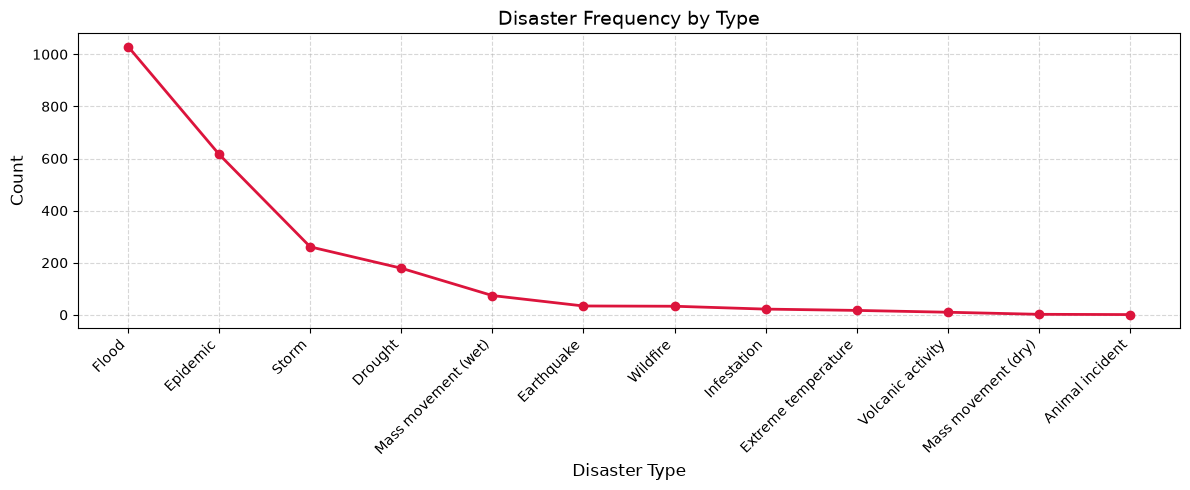

In [340]:
plt.figure(figsize=(12, 5))
plt.plot(disaster_counts.index, disaster_counts.values, marker='o', color='crimson', linewidth=2)

plt.title('Disaster Frequency by Type', fontsize=14)
plt.xlabel('Disaster Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights on disaster types**
The  analysis of disaster types shows that floods are the most frequently recorded disasters, with 1,030 cases, followed by epidemics with 616 cases and storms with 261 cases. Droughts account for 179 cases, while wet mass movements account for 74 cases. Earthquakes and wildfires have 34 and 33 cases, respectively. Infestations, extreme temperatures, volcanic activity, dry mass movements, and animal incidents are less common, with 22, 17, 10, 2, and 1 cases, respectively.

Overall, the analysis indicates that floods and epidemics dominate the dataset, suggesting that these disaster types account for a substantial proportion of recorded events. Understanding their frequency can help identify disaster patterns and inform disaster preparedness and resource allocation.

#### **Bivariate Analysis**

In [341]:
df_2.columns

Index(['Historic', 'Disaster Type', 'ISO', 'Country', 'Subregion', 'Region',
       'Location', 'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI'],
      dtype='str')

In [342]:
df_2["Estimated Deaths"].value_counts()

Estimated Deaths
8       204
14      125
58      112
13      103
1        87
       ... 
249       1
2287      1
145       1
384       1
1166      1
Name: count, Length: 267, dtype: int64

In [343]:

disaster_deaths = df_2.groupby("Disaster Type")["Estimated Deaths"].sum().reset_index()
disaster_deaths = disaster_deaths.sort_values(by="Estimated Deaths", ascending=True)
print(disaster_deaths)

          Disaster Type  Estimated Deaths
0       Animal incident                12
7   Mass movement (dry)               114
10    Volcanic activity               264
6           Infestation               352
4   Extreme temperature               416
11             Wildfire               604
8   Mass movement (wet)              4235
2            Earthquake              7593
9                 Storm             20606
1               Drought             31204
5                 Flood             31944
3              Epidemic            102580


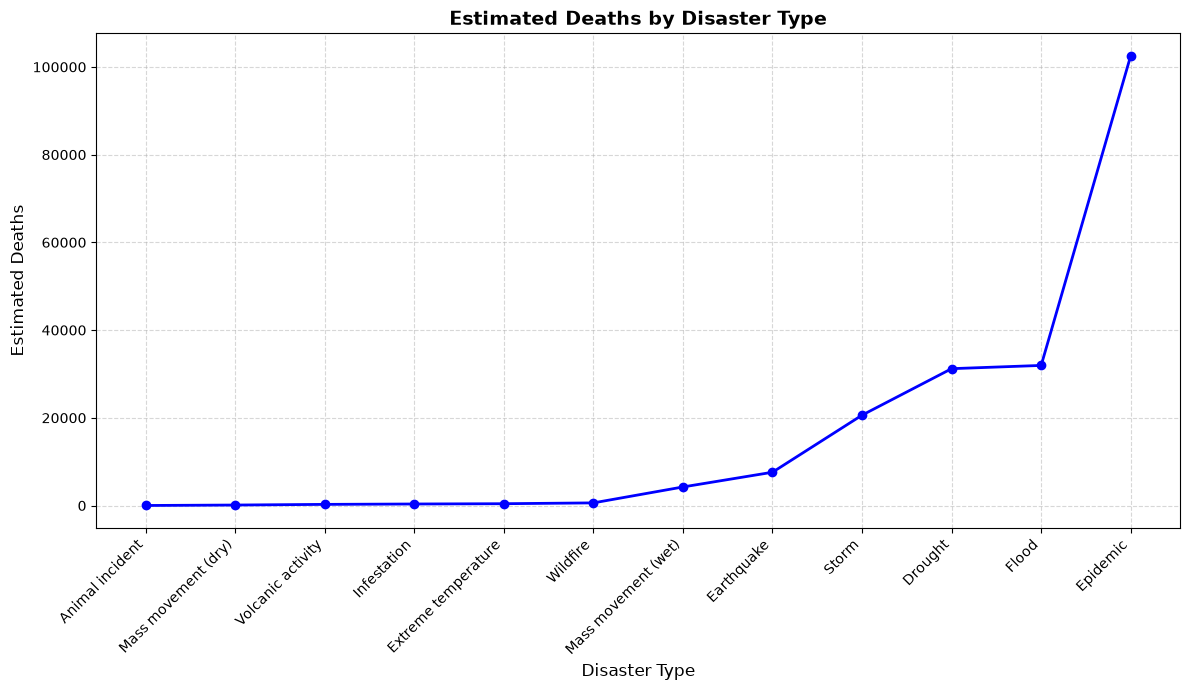

In [344]:
plt.figure(figsize=(12, 7))
plt.plot(
    disaster_deaths["Disaster Type"],
    disaster_deaths["Estimated Deaths"],
    marker="o",
    linewidth=2,
    color="blue",
)

plt.title("Estimated Deaths by Disaster Type", fontsize=14, fontweight="bold")
plt.xlabel("Disaster Type", fontsize=12)
plt.ylabel("Estimated Deaths", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### **Insights**
- Epidemics account for the highest total estimated fatalities with 102,580 deaths. 
- Floods (31,944 deaths) and Droughts (31,204 deaths) represent the second and third most fatal categories
- Storms (20,606 deaths) and Earthquakes (7,593 deaths) form the secondary cluster of high-fatality disaster types

#### **Multivariate Analysis**

In [376]:
grouped_deaths = df.groupby(['Disaster Type', 'Country','End Year','Start Year'])['Estimated Deaths'].sum().reset_index()
print(grouped_deaths.sort_values( by='Estimated Deaths',ascending=False).head(15))


     Disaster Type                           Country  End Year  Start Year  \
140        Drought                           Somalia      2011        2010   
1503         Storm                             Libya      2023        2023   
415       Epidemic                           Liberia      2016        2014   
636       Epidemic                          Zimbabwe      2009        2008   
334       Epidemic  Democratic Republic of the Congo      2019        2019   
533       Epidemic                      Sierra Leone      2015        2014   
302       Epidemic                             Congo      2019        2019   
507       Epidemic                           Nigeria      2021        2021   
195     Earthquake                           Morocco      2023        2023   
849          Flood  Democratic Republic of the Congo      2023        2023   
388       Epidemic                            Guinea      2015        2014   
163        Drought                            Uganda      2022  

In [369]:
top15_deaths = grouped_deaths.sort_values(by='Estimated Deaths', ascending=False).head(15)

In [370]:
heatmap_matrix = top15_deaths.pivot(
    index='Disaster Type',   
    columns='Country',  
    values='Estimated Deaths'
).fillna(0)

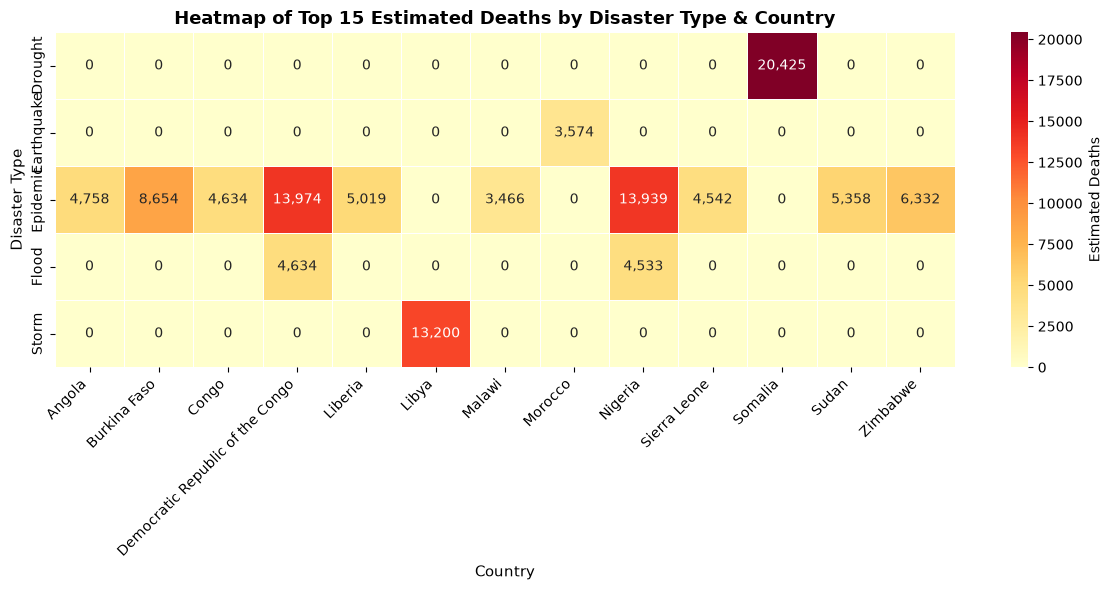

In [ ]:
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_matrix, 
    annot=True, 
    fmt=',.0f', 
    cmap='YlOrRd', 
    linewidths=0.5,
    cbar_kws={'label': 'Estimated Deaths'}
)

plt.title('Heatmap of Top 15 Estimated Deaths by Disaster Type & Country', fontsize=13, fontweight='bold')
plt.xlabel('Country', fontsize=11)
plt.ylabel('Disaster Type', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### **Insights**
- Most Severe Single Event: Somalia experienced the single highest loss of life, with 20,000 deaths resulting from the 2010–2011 Drought
- Recent High-Impact Events (2023): Libya suffered severe casualties from a 2023 Storm (13,200 deaths), while DR Congo experienced major Flooding in 2023 (2,874 deaths) alongside its earlier 2018–2019 Epidemics (6,426 combined deaths).
- Widespread Health Crises: The 2014–2016 West African Ebola outbreak accounts for major epidemic fatalities across Liberia (2014–2016), Sierra Leone (2014–2015), and Guinea (2014–2015)

## **Data preparation**

In [346]:
df_2.head(3)

,Historic,Disaster Type,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI
0,No,Flood,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,No,No,2026,3.0,6.0,2026,59,NaN,27.0,NaN
1,No,Epidemic,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,No,No,2025,1.0,7.0,2025,776,NaN,27728.0,100.0
2,No,Drought,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,No,Yes,2025,1.0,NaN,2026,58,6500000.0,6500000.0,100.0


In [347]:
df_3 = pd.get_dummies(df_2, columns=["Disaster Type"], prefix="Disaster", dtype=int)

In [348]:
df_3.columns

Index(['Historic', 'ISO', 'Country', 'Subregion', 'Region', 'Location',
       'OFDA/BHA Response', 'Appeal', 'Declaration', 'Start Year',
       'Start Month', 'Start Day', 'End Year', 'Estimated Deaths',
       'No. Affected', 'Total Affected', 'CPI', 'Disaster_Animal incident',
       'Disaster_Drought', 'Disaster_Earthquake', 'Disaster_Epidemic',
       'Disaster_Extreme temperature', 'Disaster_Flood',
       'Disaster_Infestation', 'Disaster_Mass movement (dry)',
       'Disaster_Mass movement (wet)', 'Disaster_Storm',
       'Disaster_Volcanic activity', 'Disaster_Wildfire'],
      dtype='str')

In [349]:
pd.DataFrame.describe(df_3)

,Start Year,Start Month,Start Day,End Year,Estimated Deaths,No. Affected,Total Affected,CPI,Disaster_Animal incident,Disaster_Drought,Disaster_Earthquake,Disaster_Epidemic,Disaster_Extreme temperature,Disaster_Flood,Disaster_Infestation,Disaster_Mass movement (dry),Disaster_Mass movement (wet),Disaster_Storm,Disaster_Volcanic activity,Disaster_Wildfire
count,2279.000000,2229.000000,1649.000000,2279.000000,2279.000000,1.679000e+03,2.085000e+03,2244.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000,2279.000000
mean,2011.808688,5.980260,14.067920,2011.943835,87.724441,3.574611e+05,2.905224e+05,71.202266,0.000439,0.078543,0.014919,0.270294,0.007459,0.451953,0.009653,0.000878,0.032470,0.114524,0.004388,0.014480
std,7.872965,3.627341,9.187053,7.891795,576.110234,1.492437e+06,1.346474e+06,13.089860,0.020947,0.269084,0.121255,0.444209,0.086064,0.497795,0.097798,0.029617,0.177285,0.318516,0.066110,0.119485
min,2000.000000,1.000000,1.000000,2000.000000,1.000000,1.000000e+00,1.000000e+00,53.487737,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,3.000000,6.000000,2005.000000,8.000000,1.000000e+03,7.500000e+02,60.660332,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2011.000000,6.000000,14.000000,2011.000000,15.000000,9.935000e+03,5.733000e+03,67.731095,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2019.000000,9.000000,22.000000,2019.000000,44.000000,8.481200e+04,5.025400e+04,79.410785,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2026.000000,12.000000,31.000000,2026.000000,20000.000000,2.597281e+07,2.597281e+07,100.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [350]:
columns_to_encode = ['Historic', 'Appeal', 'Declaration']

for col in columns_to_encode:  df_3[col] = df_3[col].map({'Yes': 1, 'No': 0})

In [351]:
df_3.head(3)

,Historic,ISO,Country,Subregion,Region,Location,OFDA/BHA Response,Appeal,Declaration,Start Year,...,Disaster_Earthquake,Disaster_Epidemic,Disaster_Extreme temperature,Disaster_Flood,Disaster_Infestation,Disaster_Mass movement (dry),Disaster_Mass movement (wet),Disaster_Storm,Disaster_Volcanic activity,Disaster_Wildfire
0,0,KEN,Kenya,Sub-Saharan Africa,Africa,"Mombasa, Kwale, Kilifi, Tana River, Lamu, Tait...",No,0,0,2026,...,0,0,0,1,0,0,0,0,0,0
1,0,AGO,Angola,Sub-Saharan Africa,Africa,Cacuaco (Luanda province); Bengo; Icolo e Beng...,No,0,0,2025,...,0,1,0,0,0,0,0,0,0,0
2,0,SOM,Somalia,Sub-Saharan Africa,Africa,"Gedo, Hiran, Bay, Bakool, Mudug, Bari, Toghdhe...",No,0,1,2025,...,0,0,0,0,0,0,0,0,0,0


In [352]:
df_4 = df_3.drop(columns=["ISO", "Region", "Location","No. Affected","Total Affected"]).copy()

In [353]:
df_4["OFDA/BHA Response"] = df_4["OFDA/BHA Response"].map({"Yes": 1, "No": 0})

In [354]:
df_4 = pd.get_dummies(df_4, columns=["Country", "Subregion"], dtype=int)

In [355]:
missing_cols = df_4.isnull().sum()[df_4.isnull().sum() > 0]
print(missing_cols)

Start Month     50
Start Day      630
CPI             35
dtype: int64


## **Modeling**

##### **Classical models**

In [356]:
y = np.log1p(df_4["Estimated Deaths"])
X = df_4.drop(columns=["Estimated Deaths"])

In [357]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [358]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [359]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

In [360]:

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=15,
                                           min_samples_leaf=2, random_state=42, n_jobs=-1),
    
}


In [361]:
 
def evaluate(name, y_true_log, y_pred_log):
    """Report metrics on the log scale and on the real deaths scale."""
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)
    return {
        "Model": name,
        "R2 (log)": r2_score(y_true_log, y_pred_log),
        "RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (deaths)": mean_absolute_error(y_true, y_pred),
        "RMSE (deaths)": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

In [362]:
results, preds = [], {}
for name, model in models.items():
    
    if name == "Linear Regression":
        model.fit(X_train_sc, y_train)
        p = model.predict(X_test_sc)
    else:
        model.fit(X_train, y_train)
        p = model.predict(X_test)
    preds[name] = p
    results.append(evaluate(name, y_test, p))
    

In [363]:
joblib.dump(models["Linear Regression"], "linear_regression.joblib")
joblib.dump(models["Decision Tree"], "decision_tree.joblib")
joblib.dump(models["Random Forest"], "random_forest.joblib")

['random_forest.joblib']

In [364]:
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
xgb_results = evaluate("XGBoost", y_test, y_pred_xgb)
print(pd.DataFrame([xgb_results]).round(3))


     Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  XGBoost     0.336         1.1        62.684        269.082


In [365]:
joblib.dump(xgb_model, "xgb.joblib")

['xgb.joblib']

## **Evaluation**

In [366]:
results_df = pd.DataFrame(results)
print(results_df)

               Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  Linear Regression  0.279864    1.145357     67.748910     304.591034
1      Decision Tree  0.112361    1.271603     64.793781     238.663144
2      Random Forest  0.255951    1.164217     61.350821     251.004778


In [367]:
print(pd.DataFrame([xgb_results]).round(3))

     Model  R2 (log)  RMSE (log)  MAE (deaths)  RMSE (deaths)
0  XGBoost     0.336         1.1        62.684        269.082


##### **Insights**
1. Linear Regression
- It performed the worst, with an R² of 0.302.
- Its average prediction error was approximately 67 deaths.
- This suggests that a simple straight-line relationship may not capture all the patterns in disaster fatalities.
2. Decision Tree
- It performed slightly better than Linear Regression.
- Its MAE decreased from 67 to approximately 62 deaths.
- This suggests that the relationships in the data may be more complex than Linear Regression can capture.
3. Random Forest
- It performed much better than both Linear Regression and the single Decision Tree.
- Its average prediction error was approximately 57 deaths.
- It also had a lower RMSE, suggesting fewer or smaller large prediction errors overall than the earlier models.
4. XGBoost
- It achieved the highest R² (log), at 0.494.
- It had the lowest MAE, at approximately 57 deaths, and the lowest RMSE, at approximately 258 deaths.
- However, its improvement over Random Forest was small: MAE improved by only about 0.23 deaths, and RMSE improved by about 1.46 deaths.
One important point: the MAE and RMSE values are measured in deaths, but they don't tell us whether the model performs well specifically on the most severe disasters. You should investigate those cases separately